In [ ]:
'''
finding the magnitude limits for the CNN
'''

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import os

In [2]:
import review_findings_functions as rff

In [3]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [ ]:
#ultimately we want to get this number of magnitudes:
''''
field 686 in both i and g
field 640 in both i and g
field 449 in r
and i guess each of these is four quadrants
'''

In [ ]:
#i have plotted the brightest g band gaia in ds9


In [4]:
path = '/lustre/lrspec/ZTF_data/2022/1020/'

In [14]:
!ls /lustre/lrspec/ZTF_data/2022/1020/*x.fits.fz | wc -l

128


In [15]:
!ls /lustre/lrspec/ZTF_data/2022/1020/*x.fits.fz

/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c01_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c02_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c03_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c04_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c05_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c06_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c07_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c08_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c09_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c10_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c11_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c12_x.fits.fz
/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c13_x.fits.fz

In [18]:
file = 'ztf_20221020148032_000686_zg_c01_x.fits.fz'

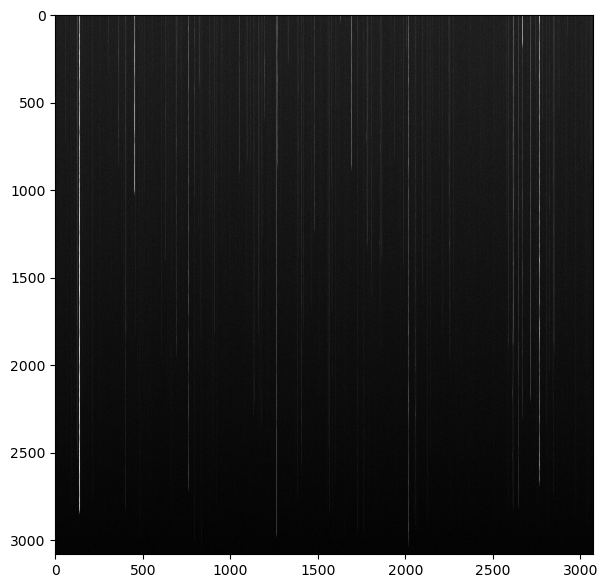

In [19]:
hdul_start = fits.open(path+file)
plt.imshow(np.sqrt(hdul_start[1].data[::-1]))

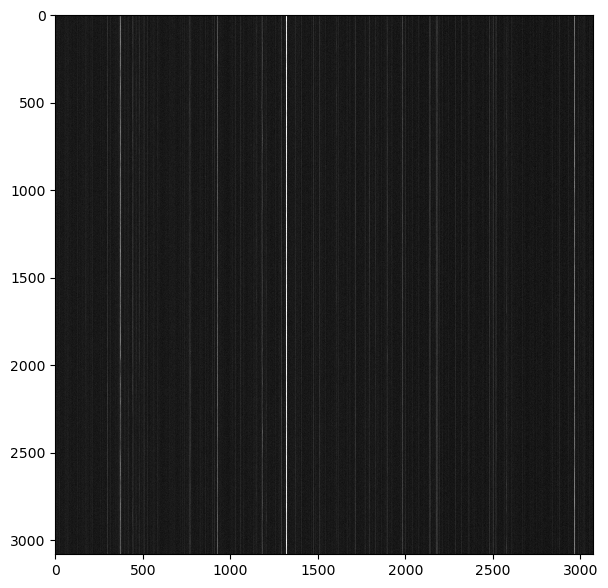

In [81]:
midfile = 'ztf_20221020148032_000686_zg_c16_x_0001.fits.fz'
hdul_mid = fits.open(path+midfile)
plt.imshow(np.log1p(hdul_mid[1].data[::-1]))

In [41]:
extpath = '/lustre/lrspecztf_20221020294271_000449_zr_c13_x_0017.fits.fz/ZTF_data/science_extractions/1020/'

In [82]:
predsarray_midfile = np.load(extpath+'ztf_20221020148032_000686_zg_c16_x_0001._extraction_predsarray_1_predsarray.npy')

In [83]:
nrow, ncol = hdul_mid[1].data.shape
wid=10

pimg_pos = predsarray_midfile[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_bg = predsarray_midfile[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_streak = predsarray_midfile[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_neg = predsarray_midfile[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_cr = predsarray_midfile[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)

In [84]:
pimg_streak_max = (np.argmax(predsarray_midfile, axis=1)==4)
pimg_streak_max = pimg_streak_max.reshape(ncol - 2 * wid, nrow - 2 * wid)

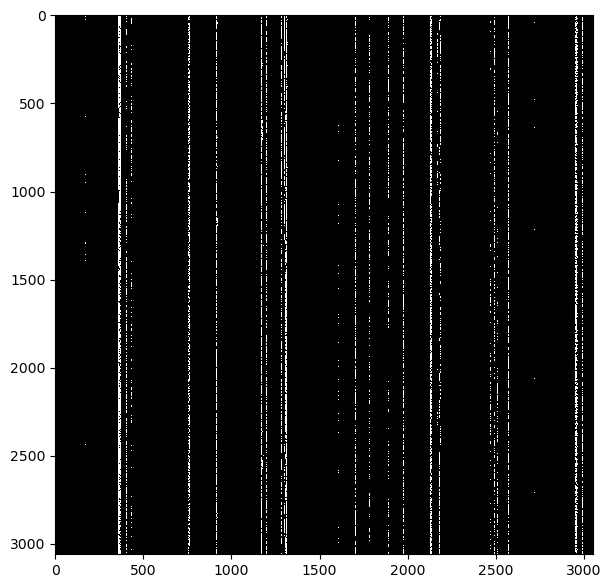

In [60]:
plt.imshow(pimg_streak_max.T)

In [ ]:
#looks like - generously - 22ish streaks
#gaia has 21 streaks below gmag 11
#and gaia only sees about half of the image
#the ten brightest gaia streaks are mags 7.3 to 10.3
#we would have trained on approximately the brightest five of those, 7.3 to 9.6

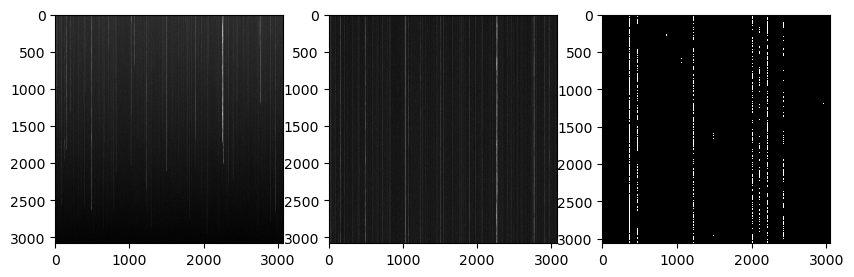

In [72]:
#let's do it again for i band in the same field (686)

file_start = 'ztf_20221020138241_000686_zi_c02_x.fits.fz'
predsarray_file = 'ztf_20221020138241_000686_zi_c02_x_0002._extraction_predsarray_1_predsarray.npy'
midfile = 'ztf_20221020138241_000686_zi_c02_x_0002.fits.fz'

fig, ax = plt.subplots(1,3)
hdul_start = fits.open(path+file_start)
ax[0].imshow(np.log1p(hdul_start[1].data[::-1]))


hdul_mid = fits.open(path+midfile)
ax[1].imshow(np.log1p(hdul_mid[1].data[::-1]))

predsarray_midfile = np.load(extpath+predsarray_file)
pimg_streak_max = (np.argmax(predsarray_midfile, axis=1)==4)
pimg_streak_max = pimg_streak_max.reshape(ncol - 2 * wid, nrow - 2 * wid)
ax[2].imshow(pimg_streak_max.T[::-1])

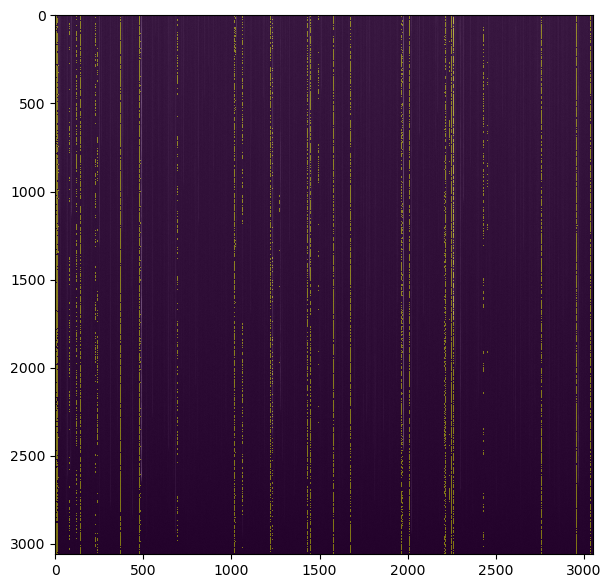

In [75]:
plt.imshow(np.log1p(hdul_start[1].data[::-1]))
plt.imshow(pimg_streak_max.T[::-1], alpha=.5, cmap='viridis')

In [ ]:
#it's a little hard to tell but let's assume they are the same
#in RP for some reason due to mismatch the gaia catalogue is only like 
#a quarter of the field (questionable)
#we detect like 24 streaks from cnn
#the top six rpmag stars from gaia are 8.7 to 9.7
#so that's approximately what we detect
#and we would have trained on like the top three (statistics getting really sketchy here)
#so that's 8.7 to 9.3

In [ ]:
#so we can try to scale by the fluxes
# for the first one:

Text(0.5, 1.0, 'Integrated Streak Flux per x coordinate and CNN streak prediction')

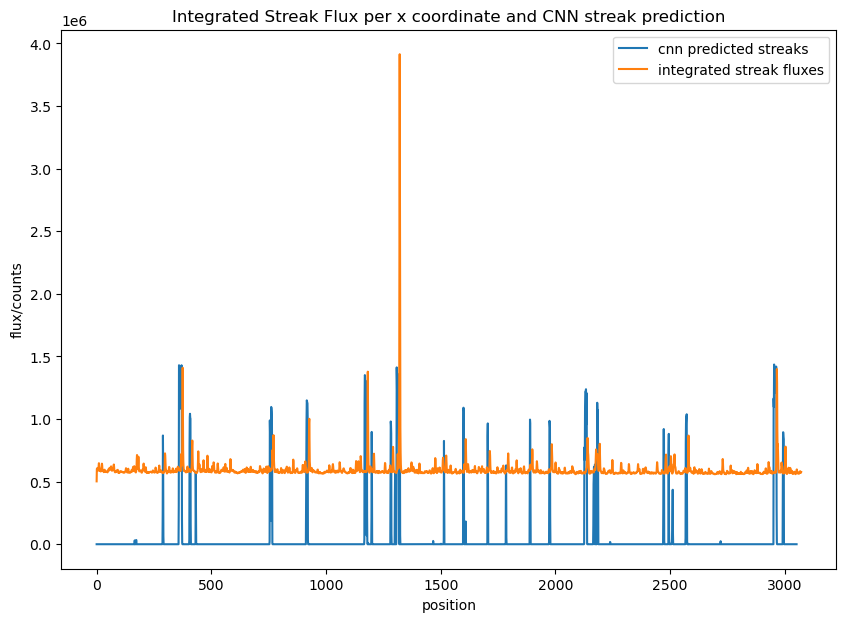

In [127]:
plt.plot(np.sum(pimg_streak_max.T, axis=0)*500, label="cnn predicted streaks")
plt.plot(np.sum(hdul_mid[1].data,axis=0), label='integrated streak fluxes')
plt.legend()
plt.xlabel("position")
plt.ylabel("flux/counts")
plt.title("Integrated Streak Flux per x coordinate and CNN streak prediction")

Text(0.5, 1.0, 'Integrated Streak Flux per x coordinate and CNN streak prediction')

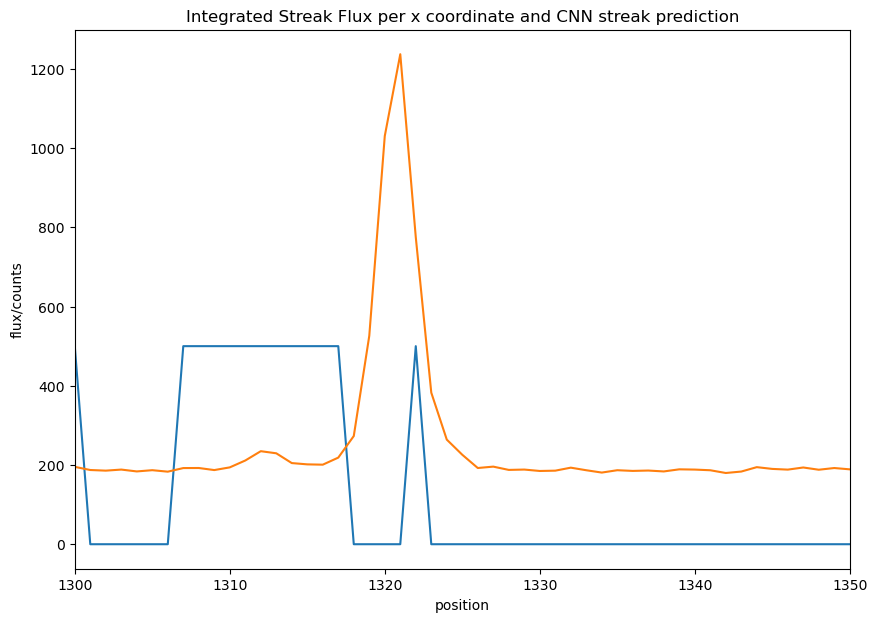

In [128]:
plt.plot(pimg_streak_max.T[1500]*500)
plt.plot(hdul_mid[1].data[1500])
plt.xlim(1300,1350)
plt.xlabel("position")
plt.ylabel("flux/counts")
plt.title("Integrated Streak Flux per x coordinate and CNN streak prediction")

In [93]:
#brightest
#this is at mag 7.3559
array, maxcols = rff.get_tot_streak(hdul_mid[1].data, col=1322, tracking=True, half_aperture=2)

Text(0.5, 1.0, 'light curve for brightest star')

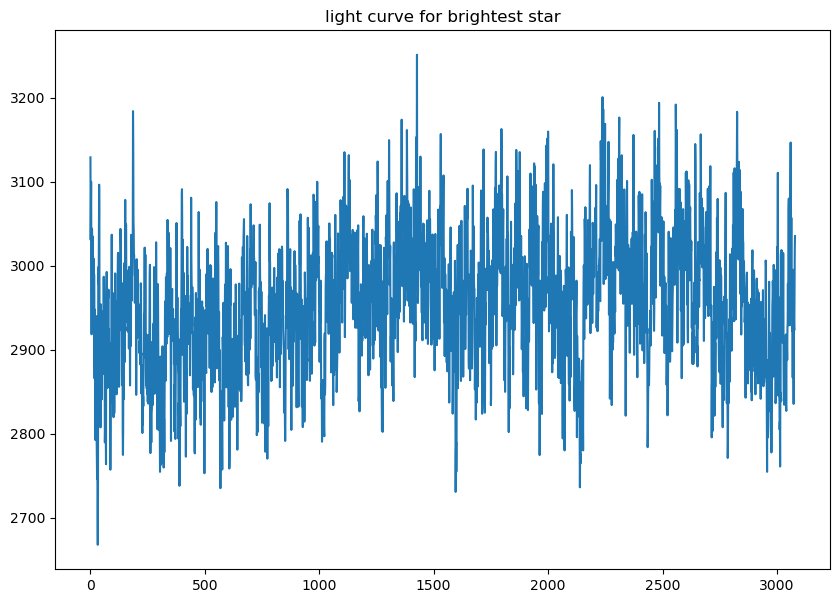

In [129]:
plt.plot(array)
plt.title("light curve for brightest star")

Text(0.5, 1.0, 'Integrated Streak Flux per x coordinate and CNN streak prediction')

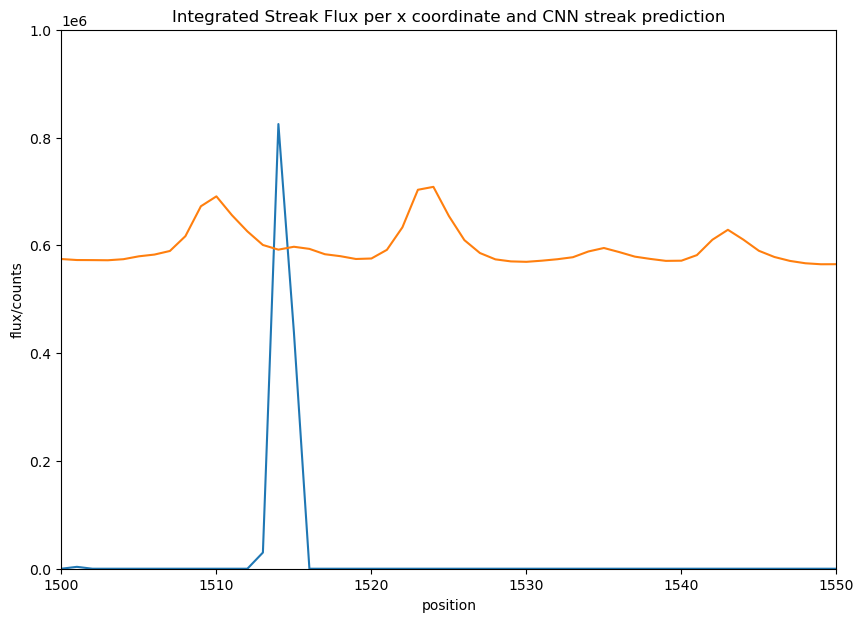

In [130]:
#now to find dimmest
plt.plot(np.sum(pimg_streak_max.T, axis=0)*500)
plt.plot(np.sum(hdul_mid[1].data,axis=0))
plt.xlim(1500,1550)
plt.ylim(0, 1e6)
plt.xlabel("position")
plt.ylabel("flux/counts")
plt.title("Integrated Streak Flux per x coordinate and CNN streak prediction")

In [112]:
#dimmest

array_dim, maxcols_dim = rff.get_tot_streak(hdul_mid[1].data, col=1525, tracking=True, half_aperture=2)

Text(0.5, 1.0, 'light curve for a dimmer star (not the dimmest)')

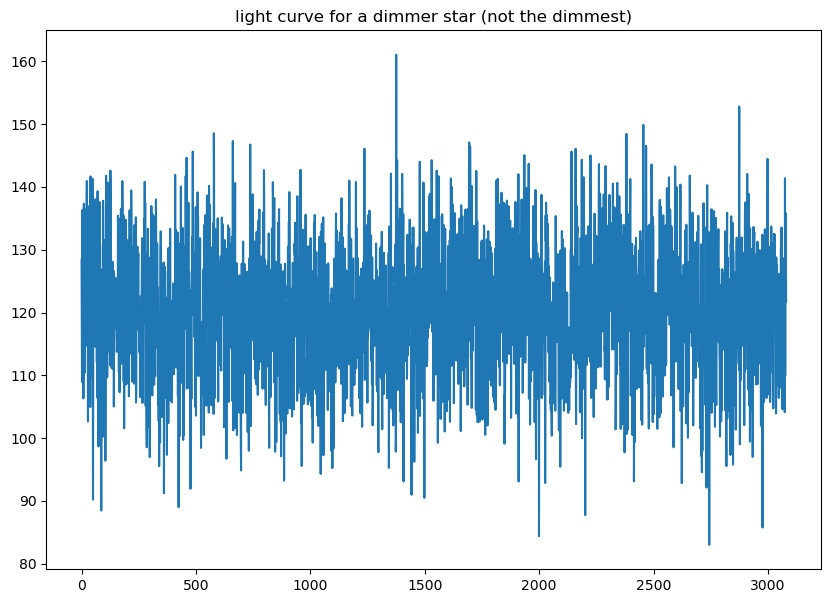

In [131]:
plt.plot(array_dim)
plt.title("light curve for a dimmer star (not the dimmest)")

In [ ]:
#dimmest starts off the gaia area

In [ ]:
#offset in x is: 1098-1320: streak is 222 to the right

#1951+222=2173 for the dimmest im plotting rn in gaia2

Text(0.5, 1.0, 'Integrated Streak Flux per x coordinate and CNN streak prediction')

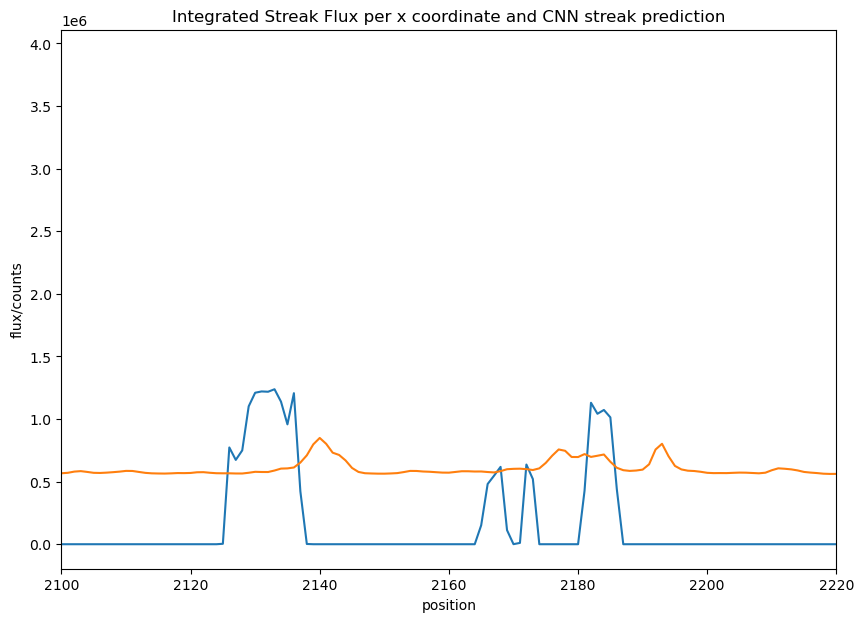

In [132]:
#now to find dimmest
plt.plot(np.sum(pimg_streak_max.T, axis=0)*500)
plt.plot(np.sum(hdul_mid[1].data,axis=0))
plt.xlim(2100,2220)
# plt.ylim(0, 1e6)
plt.xlabel("position")
plt.ylabel("flux/counts")
plt.title("Integrated Streak Flux per x coordinate and CNN streak prediction")

In [ ]:
#but this is not the dimmest one detected, there are dimmer ones
#plotting dimmer gaia stars now


In [116]:
#new dimmest at 
1658+222

1880

Text(0.5, 1.0, 'Integrated Streak Flux per x coordinate and CNN streak prediction')

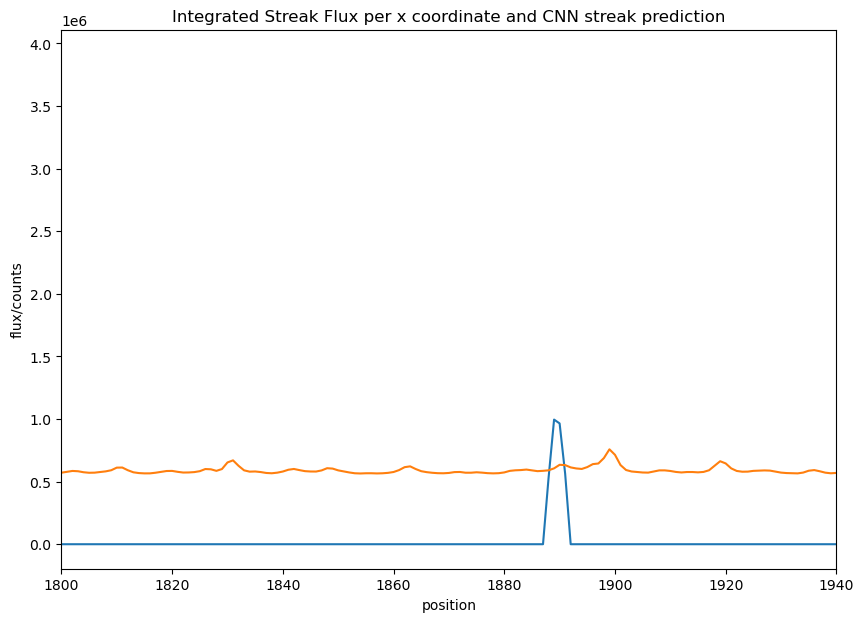

In [133]:
#now to find dimmest
plt.plot(np.sum(pimg_streak_max.T, axis=0)*500)
plt.plot(np.sum(hdul_mid[1].data,axis=0))
plt.xlim(1800,1940)
# plt.ylim(0, 1e6)
plt.xlabel("position")
plt.ylabel("flux/counts")
plt.title("Integrated Streak Flux per x coordinate and CNN streak prediction")

Text(0.5, 1.0, 'Integrated Streak Flux per x coordinate and CNN streak prediction')

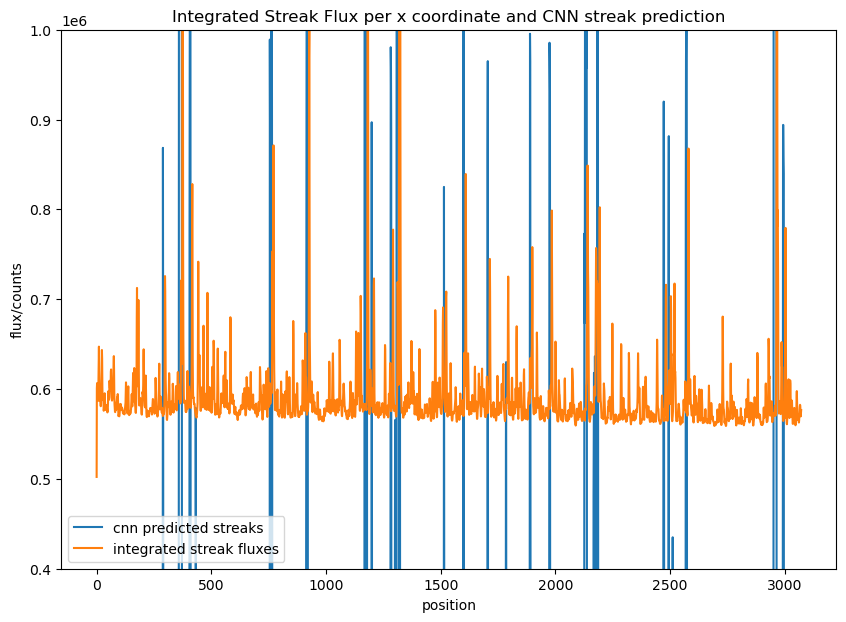

In [134]:
plt.plot(np.sum(pimg_streak_max.T, axis=0)*500, label="cnn predicted streaks")
plt.plot(np.sum(hdul_mid[1].data,axis=0), label='integrated streak fluxes')
plt.ylim(.4e6,1e6)
plt.legend()
plt.xlabel("position")
plt.ylabel("flux/counts")
plt.title("Integrated Streak Flux per x coordinate and CNN streak prediction")

In [ ]:
#so there are ones a little dimmer than that, and that's twelvth magnitude!
#except that i'm not confident it's that one 
#and not a star that starts out of gaia's realm